# Réseau piéton

In [3]:
# Geneva Cycle & Pedestrian Network Analysis
# -------------------------------------------------
# This script downloads Open data for the Canton of Geneva. 
# Only run section 5. to dowload data and save the network into segments
# -------------------------------------------------

import osmnx as ox
import os
import geopandas as gpd
import pandas as pd
import folium
from shapely.geometry import LineString
from shapely.ops import nearest_points
from shapely.ops import unary_union
from shapely.geometry import Point
import networkx as nx
from shapely.ops import substring

from tqdm import tqdm

## Segmentation du réseau et export du fichier

In [4]:
operation_crs = "EPSG:2056"  # Swiss coordinate system
target_crs = "EPSG:4326"  # WGS84 coordinate system

print("Set parameters : GG or GE or OTC, bike or walk")
territory = 'GG' # GG or GE or VD or FR or OTC
network = "walk"  # walk or bike

input_file_path = '../../Data/input'
output_step1_path=f"../../Data/output/{network}/{territory}/step-1"
output_step2_path=f"../../Data/output/{network}/{territory}/step-2"
output_step3_path=f"../../Data/output/{network}/{territory}/step-3"
save_path = f"../../Data/output/{network}/{territory}/step-1"
nodes_graph_path = f"{input_file_path}/network{territory}/{network}_nodes_graph.geojson"
edges_graph_path = f"{input_file_path}/network{territory}/{network}_edges_graph.geojson"


def fetch_network(network: str, path: str, operation_crs: str = "EPSG:2056"):
    """
    Load walk or bike network (edges) as GeoDataFrame and project to operation_crs.

    Parameters
    ----------
    network : str
        "walk" or "bike" (only for semantic check)
    path : str
        Path to the network file (geojson/shp)
    operation_crs : str
        Target CRS (default: EPSG:2056)

    Returns
    -------
    GeoDataFrame
    """
    if network not in {"walk", "bike"}:
        raise ValueError("network must be 'walk' or 'bike'")

    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")

    net = gpd.read_file(path)

    # If the file has no CRS, you MUST set it manually before projecting
    if net.crs is None:
        raise ValueError(
            f"{path} has no CRS. Set it first, e.g.: net = net.set_crs('EPSG:4326')"
        )

    net = net.to_crs(operation_crs)
    return net

Set parameters : GG or GE or OTC, bike or walk


In [5]:
#import network
print("Loading pedestrian segments, replace file path -->")

net = fetch_network(
    network,
    path=edges_graph_path,
    operation_crs=operation_crs
)



Loading pedestrian segments, replace file path -->


In [6]:
net.head()

,u,v,key,walk_class,source,highway,osm_id,id,element,footway,...,tracktype,surface,smoothness,len_m,walk_role,proxy_dedicated_covered_len_m,proxy_dedicated_coverage_ratio,edge_id,length,geometry
0,0,3996,0,walk_dedicated,OSM_highway_dedicated,footway,way/4272878,4272878.0,way,None,...,None,concrete,None,5.920195,dedicated,NaN,NaN,0,5.920195,"LINESTRING (2498336.577 1117565.487, 2498341.8..."
1,1,2,0,walk_track,OSM_highway_dedicated,track,way/4297439,4297439.0,way,None,...,grade2,None,None,701.230056,dedicated,NaN,NaN,1,277.157683,"LINESTRING (2495505.256 1128846.191, 2495317.7..."
2,2,3,0,walk_track,OSM_highway_dedicated,track,way/4297439,4297439.0,way,None,...,grade2,None,None,701.230056,dedicated,NaN,NaN,1,80.468529,"LINESTRING (2495317.711 1129050.258, 2495254.6..."
3,3,4,0,walk_track,OSM_highway_dedicated,track,way/4297439,4297439.0,way,None,...,grade2,None,None,701.230056,dedicated,NaN,NaN,1,60.478127,"LINESTRING (2495254.647 1129100.239, 2495207.7..."
4,4,183600,0,walk_track,OSM_highway_dedicated,track,way/4297439,4297439.0,way,None,...,grade2,None,None,701.230056,dedicated,NaN,NaN,1,283.125716,"LINESTRING (2495207.737 1129138.41, 2495161.51..."


**Stats on the network - not working with networkGG**

In [7]:
'''# Add Length column in meters
net['length_m'] = net.geometry.length

# DETAILED NETWORK STATISTICS
print("\n" + "="*100)
print("DETAILED PEDESTRIAN NETWORK STATISTICS - GENEVA")
print("="*100)

# Calculate total length once for percentage calculations
total_length_km = net['length_m'].sum() / 1000

# 1. BASIC NETWORK INFORMATION
print("\n1. BASIC NETWORK INFORMATION")
print("-" * 100)
print(f"Total number of edges: {len(net):,}")
print(f"Total network length: {total_length_km:.2f} km")
print(f"Mean edge length: {net['length_m'].mean():.2f} m")
print(f"Median edge length: {net['length_m'].median():.2f} m")

# 2. SIDEWALK WIDTH DISTRIBUTION (Largeur)
print("\n2. SIDEWALK WIDTH DISTRIBUTION (Largeur)")
print("-" * 100)
n_missing = net['Largeur'].isna().sum() | (net['Largeur'] == 'None').sum() | (net['Largeur'] == '').sum()
if n_missing > 0:
    length_missing = net[net['Largeur'].isna() | (net['Largeur'] == 'None') | (net['Largeur'] == '')]['length_m'].sum() / 1000
    pct_missing_edges = (n_missing / len(net)) * 100
    pct_missing_length = (length_missing / total_length_km) * 100
    print(f"  {'⚠️  NON RENSEIGNÉ':20s}: {n_missing:6,} edges ({pct_missing_edges:5.1f}%) | {length_missing:8.2f} km ({pct_missing_length:5.1f}%)")

for width, count in net['Largeur'].value_counts(dropna=False).items():
    if pd.isna(width) or str(width) in ['None', '', 'nan']:
        continue
    length_km = net[net['Largeur'] == width]['length_m'].sum() / 1000
    pct_edges = (count / len(net)) * 100
    pct_length = (length_km / total_length_km) * 100
    print(f"  {width:20s}: {count:6,} edges ({pct_edges:5.1f}%) | {length_km:8.2f} km ({pct_length:5.1f}%)")

# 3. INFRASTRUCTURE TYPE (Objet)
print("\n3. INFRASTRUCTURE TYPE (Objet)")
print("-" * 100)
n_missing = net['Objet'].isna().sum() | (net['Objet'] == 'None').sum() | (net['Objet'] == '').sum()
if n_missing > 0:
    length_missing = net[net['Objet'].isna() | (net['Objet'] == 'None') | (net['Objet'] == '')]['length_m'].sum() / 1000
    pct_missing_edges = (n_missing / len(net)) * 100
    pct_missing_length = (length_missing / total_length_km) * 100
    print(f"  {'⚠️  NON RENSEIGNÉ':30s}: {n_missing:6,} edges ({pct_missing_edges:5.1f}%) | {length_missing:8.2f} km ({pct_missing_length:5.1f}%)")

for obj_type, count in net['Objet'].value_counts(dropna=False).items():
    if pd.isna(obj_type) or str(obj_type) in ['None', '', 'nan']:
        continue
    length_km = net[net['Objet'] == obj_type]['length_m'].sum() / 1000
    pct_edges = (count / len(net)) * 100
    pct_length = (length_km / total_length_km) * 100
    print(f"  {str(obj_type):30s}: {count:6,} edges ({pct_edges:5.1f}%) | {length_km:8.2f} km ({pct_length:5.1f}%)")

# 4. SURFACE TYPE (Revetement)
print("\n4. SURFACE TYPE (Revetement)")
print("-" * 100)
n_missing = net['Revetement'].isna().sum() | (net['Revetement'] == 'None').sum() | (net['Revetement'] == '').sum()
if n_missing > 0:
    length_missing = net[net['Revetement'].isna() | (net['Revetement'] == 'None') | (net['Revetement'] == '')]['length_m'].sum() / 1000
    pct_missing_edges = (n_missing / len(net)) * 100
    pct_missing_length = (length_missing / total_length_km) * 100
    print(f"  {'⚠️  NON RENSEIGNÉ':30s}: {n_missing:6,} edges ({pct_missing_edges:5.1f}%) | {length_missing:8.2f} km ({pct_missing_length:5.1f}%)")

for surface, count in net['Revetement'].value_counts(dropna=False).items():
    if pd.isna(surface) or str(surface) in ['None', '', 'nan']:
        continue
    length_km = net[net['Revetement'] == surface]['length_m'].sum() / 1000
    pct_edges = (count / len(net)) * 100
    pct_length = (length_km / total_length_km) * 100
    print(f"  {str(surface):30s}: {count:6,} edges ({pct_edges:5.1f}%) | {length_km:8.2f} km ({pct_length:5.1f}%)")

# 5. MIXED USE WITH BIKES (Partage_us)
print("\n5. MIXED USE WITH BIKES (Partage_us)")
print("-" * 100)
n_missing = net['Partage_us'].isna().sum() | (net['Partage_us'] == 'None').sum() | (net['Partage_us'] == '').sum()
if n_missing > 0:
    length_missing = net[net['Partage_us'].isna() | (net['Partage_us'] == 'None') | (net['Partage_us'] == '')]['length_m'].sum() / 1000
    pct_missing_edges = (n_missing / len(net)) * 100
    pct_missing_length = (length_missing / total_length_km) * 100
    print(f"  {'⚠️  NON RENSEIGNÉ':40s}: {n_missing:6,} edges ({pct_missing_edges:5.1f}%) | {length_missing:8.2f} km ({pct_missing_length:5.1f}%)")

for usage, count in net['Partage_us'].value_counts(dropna=False).items():
    if pd.isna(usage) or str(usage) in ['None', '', 'nan']:
        continue
    length_km = net[net['Partage_us'] == usage]['length_m'].sum() / 1000
    pct_edges = (count / len(net)) * 100
    pct_length = (length_km / total_length_km) * 100
    print(f"  {str(usage):40s}: {count:6,} edges ({pct_edges:5.1f}%) | {length_km:8.2f} km ({pct_length:5.1f}%)")

# 6. SPEED LIMITS (Vitesse)
print("\n6. ADJACENT ROAD SPEED LIMITS (Vitesse)")
print("-" * 100)
n_missing = net['Vitesse'].isna().sum()
if n_missing > 0:
    length_missing = net[net['Vitesse'].isna()]['length_m'].sum() / 1000
    pct_missing_edges = (n_missing / len(net)) * 100
    pct_missing_length = (length_missing / total_length_km) * 100
    print(f"  ⚠️  NON RENSEIGNÉ: {n_missing:6,} edges ({pct_missing_edges:5.1f}%) | {length_missing:8.2f} km ({pct_missing_length:5.1f}%)")

for speed, count in net['Vitesse'].value_counts(dropna=False).sort_index().items():
    if pd.isna(speed):
        continue
    length_km = net[net['Vitesse'] == speed]['length_m'].sum() / 1000
    pct_edges = (count / len(net)) * 100
    pct_length = (length_km / total_length_km) * 100
    print(f"  {speed:3d} km/h: {count:6,} edges ({pct_edges:5.1f}%) | {length_km:8.2f} km ({pct_length:5.1f}%)")

# 7. PEDESTRIAN CROSSINGS WITH TRAFFIC LIGHTS (PP_Feux)
print("\n7. PEDESTRIAN CROSSINGS WITH TRAFFIC LIGHTS (PP_Feux)")
print("-" * 100)
n_missing = net['PP_Feux'].isna().sum() | (net['PP_Feux'] == 'None').sum() | (net['PP_Feux'] == '').sum()
if n_missing > 0:
    length_missing = net[net['PP_Feux'].isna() | (net['PP_Feux'] == 'None') | (net['PP_Feux'] == '')]['length_m'].sum() / 1000
    pct_missing_edges = (n_missing / len(net)) * 100
    pct_missing_length = (length_missing / total_length_km) * 100
    print(f"  {'⚠️  NON RENSEIGNÉ':10s}: {n_missing:6,} edges ({pct_missing_edges:5.1f}%) | {length_missing:8.2f} km ({pct_missing_length:5.1f}%)")

for lights, count in net['PP_Feux'].value_counts(dropna=False).items():
    if pd.isna(lights) or str(lights) in ['None', '', 'nan']:
        continue
    length_km = net[net['PP_Feux'] == lights]['length_m'].sum() / 1000
    pct_edges = (count / len(net)) * 100
    pct_length = (length_km / total_length_km) * 100
    print(f"  {str(lights):10s}: {count:6,} edges ({pct_edges:5.1f}%) | {length_km:8.2f} km ({pct_length:5.1f}%)")

# 8. SLOPE STATISTICS (Pente)
print("\n8. SLOPE STATISTICS (Pente in %)")
print("-" * 100)
n_missing = net['Pente'].isna().sum()
if n_missing > 0:
    length_missing = net[net['Pente'].isna()]['length_m'].sum() / 1000
    pct_missing_edges = (n_missing / len(net)) * 100
    pct_missing_length = (length_missing / total_length_km) * 100
    print(f"⚠️  NON RENSEIGNÉ: {n_missing:6,} edges ({pct_missing_edges:5.1f}%) | {length_missing:8.2f} km ({pct_missing_length:5.1f}%)\n")

print(f"  Mean slope: {net['Pente'].mean():.2f}%")
print(f"  Median slope: {net['Pente'].median():.2f}%")
print(f"  Max slope: {net['Pente'].max():.2f}%")
print(f"  Min slope: {net['Pente'].min():.2f}%")

# Slope categories
slope_categories = [
    ('Flat (< 2%)', net['Pente'] < 2),
    ('Gentle (2-5%)', (net['Pente'] >= 2) & (net['Pente'] < 5)),
    ('Moderate (5-8%)', (net['Pente'] >= 5) & (net['Pente'] < 8)),
    ('Steep (>= 8%)', net['Pente'] >= 8)
]

print("\nSlope categories:")
for cat_name, mask in slope_categories:
    count = mask.sum()
    length_km = net[mask]['length_m'].sum() / 1000
    pct_edges = (count / len(net)) * 100
    pct_length = (length_km / total_length_km) * 100
    print(f"  {cat_name:20s}: {count:6,} edges ({pct_edges:5.1f}%) | {length_km:8.2f} km ({pct_length:5.1f}%)")

# 9. ROAD CLASS (Classe)
print("\n9. ROAD CLASS DISTRIBUTION (Classe)")
print("-" * 100)
n_missing = net['Classe'].isna().sum() | (net['Classe'] == 'None').sum() | (net['Classe'] == '').sum()
if n_missing > 0:
    length_missing = net[net['Classe'].isna() | (net['Classe'] == 'None') | (net['Classe'] == '')]['length_m'].sum() / 1000
    pct_missing_edges = (n_missing / len(net)) * 100
    pct_missing_length = (length_missing / total_length_km) * 100
    print(f"  {'⚠️  NON RENSEIGNÉ':20s}: {n_missing:6,} edges ({pct_missing_edges:5.1f}%) | {length_missing:8.2f} km ({pct_missing_length:5.1f}%)")

for road_class, count in net['Classe'].value_counts(dropna=False).items():
    if pd.isna(road_class) or str(road_class) in ['None', '', 'nan']:
        continue
    length_km = net[net['Classe'] == road_class]['length_m'].sum() / 1000
    pct_edges = (count / len(net)) * 100
    pct_length = (length_km / total_length_km) * 100
    print(f"  {str(road_class):20s}: {count:6,} edges ({pct_edges:5.1f}%) | {length_km:8.2f} km ({pct_length:5.1f}%)")

# 10. MODAL ZONES (Zone_mod)
print("\n10. MODAL ZONES (Zone_mod)")
print("-" * 100)
n_missing = net['Zone_mod'].isna().sum() | (net['Zone_mod'] == 'None').sum() | (net['Zone_mod'] == '').sum()
if n_missing > 0:
    length_missing = net[net['Zone_mod'].isna() | (net['Zone_mod'] == 'None') | (net['Zone_mod'] == '')]['length_m'].sum() / 1000
    pct_missing_edges = (n_missing / len(net)) * 100
    pct_missing_length = (length_missing / total_length_km) * 100
    print(f"  {'⚠️  NON RENSEIGNÉ':20s}: {n_missing:6,} edges ({pct_missing_edges:5.1f}%) | {length_missing:8.2f} km ({pct_missing_length:5.1f}%)")

for zone, count in net['Zone_mod'].value_counts(dropna=False).items():
    if pd.isna(zone) or str(zone) in ['None', '', 'nan']:
        continue
    length_km = net[net['Zone_mod'] == zone]['length_m'].sum() / 1000
    pct_edges = (count / len(net)) * 100
    pct_length = (length_km / total_length_km) * 100
    print(f"  {str(zone):20s}: {count:6,} edges ({pct_edges:5.1f}%) | {length_km:8.2f} km ({pct_length:5.1f}%)")

# 11. TOP 20 COMMUNES BY NETWORK LENGTH
print("\n11. TOP 20 COMMUNES BY NETWORK LENGTH")
print("-" * 100)
commune_stats = net.groupby('Commune').agg({
    'length_m': ['count', 'sum']
}).round(2)
commune_stats.columns = ['count', 'total_length_m']
commune_stats['total_length_km'] = commune_stats['total_length_m'] / 1000
commune_stats = commune_stats.sort_values('total_length_km', ascending=False).head(20)

for idx, (commune, row) in enumerate(commune_stats.iterrows(), 1):
    pct = (row['total_length_km'] / total_length_km) * 100
    print(f"  {idx:2d}. {commune:30s}: {int(row['count']):6,} edges | {row['total_length_km']:8.2f} km ({pct:5.1f}%)")

# 12. INFRASTRUCTURE TYPE (Type)
print("\n12. INFRASTRUCTURE TYPE DETAILS (Type)")
print("-" * 100)
n_missing = net['Type'].isna().sum() | (net['Type'] == 'None').sum() | (net['Type'] == '').sum()
if n_missing > 0:
    length_missing = net[net['Type'].isna() | (net['Type'] == 'None') | (net['Type'] == '')]['length_m'].sum() / 1000
    pct_missing_edges = (n_missing / len(net)) * 100
    pct_missing_length = (length_missing / total_length_km) * 100
    print(f"  {'⚠️  NON RENSEIGNÉ':30s}: {n_missing:6,} edges ({pct_missing_edges:5.1f}%) | {length_missing:8.2f} km ({pct_missing_length:5.1f}%)")

for infra_type, count in net['Type'].value_counts(dropna=False).items():
    if pd.isna(infra_type) or str(infra_type) in ['None', '', 'nan']:
        continue
    length_km = net[net['Type'] == infra_type]['length_m'].sum() / 1000
    pct_edges = (count / len(net)) * 100
    pct_length = (length_km / total_length_km) * 100
    print(f"  {str(infra_type):30s}: {count:6,} edges ({pct_edges:5.1f}%) | {length_km:8.2f} km ({pct_length:5.1f}%)")

# 13. CROSSINGS (Franchisse)
print("\n13. CROSSING TYPES (Franchisse)")
print("-" * 100)
n_missing = net['Franchisse'].isna().sum() | (net['Franchisse'] == 'None').sum() | (net['Franchisse'] == '').sum()
if n_missing > 0:
    length_missing = net[net['Franchisse'].isna() | (net['Franchisse'] == 'None') | (net['Franchisse'] == '')]['length_m'].sum() / 1000
    pct_missing_edges = (n_missing / len(net)) * 100
    pct_missing_length = (length_missing / total_length_km) * 100
    print(f"  {'⚠️  NON RENSEIGNÉ':30s}: {n_missing:6,} edges ({pct_missing_edges:5.1f}%) | {length_missing:8.2f} km ({pct_missing_length:5.1f}%)")

for crossing, count in net['Franchisse'].value_counts(dropna=False).items():
    if pd.isna(crossing) or str(crossing) in ['None', '', 'nan']:
        continue
    length_km = net[net['Franchisse'] == crossing]['length_m'].sum() / 1000
    pct_edges = (count / len(net)) * 100
    pct_length = (length_km / total_length_km) * 100
    print(f"  {str(crossing):30s}: {count:6,} edges ({pct_edges:5.1f}%) | {length_km:8.2f} km ({pct_length:5.1f}%)")

print("\n" + "="*100)
print("END OF DETAILED STATISTICS")
print("="*100)'''

'# Add Length column in meters\nnet[\'length_m\'] = net.geometry.length\n\n# DETAILED NETWORK STATISTICS\nprint("\n" + "="*100)\nprint("DETAILED PEDESTRIAN NETWORK STATISTICS - GENEVA")\nprint("="*100)\n\n# Calculate total length once for percentage calculations\ntotal_length_km = net[\'length_m\'].sum() / 1000\n\n# 1. BASIC NETWORK INFORMATION\nprint("\n1. BASIC NETWORK INFORMATION")\nprint("-" * 100)\nprint(f"Total number of edges: {len(net):,}")\nprint(f"Total network length: {total_length_km:.2f} km")\nprint(f"Mean edge length: {net[\'length_m\'].mean():.2f} m")\nprint(f"Median edge length: {net[\'length_m\'].median():.2f} m")\n\n# 2. SIDEWALK WIDTH DISTRIBUTION (Largeur)\nprint("\n2. SIDEWALK WIDTH DISTRIBUTION (Largeur)")\nprint("-" * 100)\nn_missing = net[\'Largeur\'].isna().sum() | (net[\'Largeur\'] == \'None\').sum() | (net[\'Largeur\'] == \'\').sum()\nif n_missing > 0:\n    length_missing = net[net[\'Largeur\'].isna() | (net[\'Largeur\'] == \'None\') | (net[\'Largeur\'] == \'

**Segment the network**

In [8]:
# Explode osmid lists so each row has a single osmid (works for lists, numpy arrays, and stringified lists)
import numpy as np
import ast
def to_osmid_list(x):
    if isinstance(x, (list, np.ndarray)):
        return list(x)
    if isinstance(x, str):
        try:
            val = ast.literal_eval(x)
            if isinstance(val, (list, np.ndarray)):
                return list(val)
            else:
                return [val]
        except Exception:
            return [x]
    return [x]

if "osmid" in net.columns:
    net["osmid"] = net["osmid"].apply(to_osmid_list)
    net = net.explode("osmid").reset_index(drop=True)

In [9]:
len(net)

339282

In [10]:
from shapely.geometry import LineString, MultiLineString
from shapely.ops import substring
import geopandas as gpd
import pandas as pd
from tqdm import tqdm

def split_linestring(geom, segment_length):
    
    """Split a LineString into segments of a given length."""
    if geom.length <= segment_length:
        return [geom]
    segments = []
    start = 0.0
    while start < geom.length:
        end = min(start + segment_length, geom.length)
        seg = substring(geom, start, end)
        segments.append(seg)
        start = end
    return segments

def split_row(row, segment_length):
    geom = row.geometry
    if geom.is_empty:
        return []
    if isinstance(geom, LineString):
        segments = split_linestring(geom, segment_length)
    elif isinstance(geom, MultiLineString):
        segments = []
        for part in geom.geoms:
            segments.extend(split_linestring(part, segment_length))
    else:
        return []
    split_rows = []
    for seg in segments:
        new_row = row.copy()
        new_row.geometry = seg
        new_row["length"] = seg.length
        split_rows.append(new_row)
    return split_rows

# Desired segment length in meters
segment_length = 50

print("Splitting LineStrings into fixed-length segments...")
split_rows = []
for idx, row in tqdm(net.iterrows(), total=len(net)):
    split_rows.extend(split_row(row, segment_length))

all_segments = gpd.GeoDataFrame(split_rows, crs=net.crs)
all_segments.reset_index(drop=True, inplace=True)
# Generate segment_id as osmid + incremental number per osmid
if "osmid" in all_segments.columns:
    all_segments["segment_id"] = None
    from collections import defaultdict
    osmid_counters = defaultdict(int)
    for idx, row in all_segments.iterrows():
        osm = str(row["osmid"])
        osmid_counters[osm] += 1
        all_segments.at[idx, "segment_id"] = f"{osm}_{str(osmid_counters[osm]).zfill(3)}"
else:
    all_segments["segment_id"] = all_segments.index.astype(str).str.zfill(6)

Splitting LineStrings into fixed-length segments...


100%|██████████| 339282/339282 [00:27<00:00, 12454.47it/s]


In [11]:
all_segments

,u,v,key,walk_class,source,highway,osm_id,id,element,footway,...,surface,smoothness,len_m,walk_role,proxy_dedicated_covered_len_m,proxy_dedicated_coverage_ratio,edge_id,length,geometry,segment_id
0,0,3996,0,walk_dedicated,OSM_highway_dedicated,footway,way/4272878,4.272878e+06,way,None,...,concrete,None,5.920195,dedicated,NaN,NaN,0,5.920195,"LINESTRING (2498336.577 1117565.487, 2498341.8...",000000
1,1,2,0,walk_track,OSM_highway_dedicated,track,way/4297439,4.297439e+06,way,None,...,None,None,701.230056,dedicated,NaN,NaN,1,50.000000,"LINESTRING (2495505.256 1128846.191, 2495471.4...",000001
2,1,2,0,walk_track,OSM_highway_dedicated,track,way/4297439,4.297439e+06,way,None,...,None,None,701.230056,dedicated,NaN,NaN,1,50.000000,"LINESTRING (2495471.423 1128883.006, 2495437.5...",000002
3,1,2,0,walk_track,OSM_highway_dedicated,track,way/4297439,4.297439e+06,way,None,...,None,None,701.230056,dedicated,NaN,NaN,1,50.000000,"LINESTRING (2495437.589 1128919.82, 2495403.75...",000003
4,1,2,0,walk_track,OSM_highway_dedicated,track,way/4297439,4.297439e+06,way,None,...,None,None,701.230056,dedicated,NaN,NaN,1,50.000000,"LINESTRING (2495403.755 1128956.634, 2495369.9...",000004
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
555370,254788,87166,0,sidewalk_proxy_road_axis,OSM_highway_proxy,service,way/1568023835,1.568024e+09,way,None,...,None,None,39.893638,proxy_local,21.280947,0.533442,201392,9.291826,"LINESTRING (2498262.992 1119689.14, 2498269.46...",555370
555371,87166,130496,0,sidewalk_proxy_road_axis,OSM_highway_proxy,service,way/1568023835,1.568024e+09,way,None,...,None,None,39.893638,proxy_local,21.280947,0.533442,201392,30.601812,"LINESTRING (2498269.463 1119682.471, 2498287.6...",555371
555372,254789,254790,0,sidewalk_proxy_road_axis,OSM_highway_proxy,service,way/1568023836,1.568024e+09,way,None,...,None,None,40.056797,proxy_local,20.177314,0.503718,201393,5.591375,"LINESTRING (2498259.113 1119685.625, 2498262.9...",555372
555373,254790,130497,0,sidewalk_proxy_road_axis,OSM_highway_proxy,service,way/1568023836,1.568024e+09,way,None,...,None,None,40.056797,proxy_local,20.177314,0.503718,201393,34.465421,"LINESTRING (2498262.973 1119681.58, 2498283.67...",555373


In [12]:
#save to gpkg file to save_path/"step1_all_segments.gpkg"
if not os.path.exists(save_path):
    os.makedirs(save_path)
output_file_gpkg = os.path.join(save_path, "step1_all_segments.gpkg")
all_segments.to_crs(target_crs).to_file(output_file_gpkg, driver="GPKG")
print(f"Segments saved to {output_file_gpkg}")
#save to geoparquet file
output_file_parquet = os.path.join(save_path, "step1_all_segments.parquet")
all_segments.to_crs(target_crs).to_parquet(output_file_parquet)
print(f"Segments saved to {output_file_parquet}")

Segments saved to ../../Data/output/walk/GG/step-1/step1_all_segments.gpkg
Segments saved to ../../Data/output/walk/GG/step-1/step1_all_segments.parquet


**Étude statistique des tags (step1_all_segments.gpkg)**

In [ ]:
# =====================================================================
# Étude statistique des tags de step1_all_segments.gpkg
#   + coverage urbain / non urbain (tache urbaine 2022 dilatée, même
#     méthode que 1_1 : milieu du segment dans la tache -> urbain)
# =====================================================================
import matplotlib.pyplot as plt
import numpy as np

# --- Paramètres à adapter ---------------------------------------------
segments_file = os.path.join(output_step1_path, "step1_all_segments.gpkg")
tache_urbaine_path = f"{input_file_path}/network_agreg/AGGLO_TACHE_URBAINE_2022.gpkg"
TACHE_BUFFER_M = 200.0     # dilatation de la tache urbaine (0 = aucune), comme dans 1_1

TAGS = ["service"]  # tags à inspecter
MISSING_VALUES = {"", "none", "nan", "null", "unclassified"}  # considérées comme "non renseigné" (comparaison en minuscules)
WEIGHT_BY_LENGTH = True   # True : proportions pondérées par la longueur des segments (colonne 'length')
TOP_N = 15                 # nb max de catégories affichées, le reste est regroupé dans "autres"
SHOW_MISSING_BAR = True    # afficher la barre "non renseigné" dans l'histogramme
N_COLS = 2                 # nb de tags par ligne

# --- Chargement --------------------------------------------------------
seg = gpd.read_file(segments_file).to_crs(operation_crs)
print(f"{len(seg):,} segments chargés depuis {segments_file}")

# --- Urbain / non urbain : milieu du segment dans la tache urbaine ------
tache_urbaine = gpd.read_file(tache_urbaine_path)
tache_urbaine["geometry"] = tache_urbaine.geometry.force_2d().make_valid()
tache_urbaine = tache_urbaine.to_crs(operation_crs)[["geometry"]]
if TACHE_BUFFER_M > 0:
    tache_urbaine["geometry"] = tache_urbaine.geometry.buffer(TACHE_BUFFER_M)

mid = gpd.GeoDataFrame(geometry=seg.geometry.interpolate(0.5, normalized=True),
                       index=seg.index, crs=operation_crs)
in_tache = gpd.sjoin(mid, tache_urbaine, how="inner", predicate="intersects").index.unique()
is_urban = pd.Series(seg.index.isin(in_tache), index=seg.index)
print(f"Segments urbains : {is_urban.sum():,} ({100 * is_urban.mean():.1f} %) | "
      f"non urbains : {(~is_urban).sum():,} ({100 * (~is_urban).mean():.1f} %)")

# Liste des tags candidats, pour t'aider à remplir TAGS
id_cols = {"u", "v", "key", "osm_id", "osmid", "id", "edge_id", "segment_id", "length", "len_m", "geometry"}
candidates = [c for c in seg.columns
              if c not in id_cols and (seg[c].dtype == object or seg[c].nunique(dropna=True) <= 50)]
print("Tags disponibles :", candidates)

absent = [t for t in TAGS if t not in seg.columns]
if absent:
    print("⚠️  Tags absents du fichier, ignorés :", absent)
tags = [t for t in TAGS if t in seg.columns]

if WEIGHT_BY_LENGTH and "length" in seg.columns:
    weights, unit = seg["length"].fillna(0), "de la longueur"
else:
    weights, unit = pd.Series(1.0, index=seg.index), "des segments"
total_w = weights.sum()


def split_missing(s):
    """Renvoie (valeurs en texte, masque des valeurs non renseignées)."""
    s_str = s.astype("string").str.strip()
    is_missing = s.isna() | s_str.str.lower().isin(MISSING_VALUES).fillna(True)
    return s_str.where(~is_missing), is_missing


def coverage_pct(is_missing, mask, w=None):
    """% des segments (ou de la longueur si w) renseignés dans le sous-ensemble mask."""
    if mask.sum() == 0:
        return np.nan
    w = pd.Series(1.0, index=mask.index) if w is None else w
    return 100 * w[mask & ~is_missing].sum() / w[mask].sum()


# --- Calcul + graphiques ------------------------------------------------
coverage_rows = []
n_rows = int(np.ceil(len(tags) / N_COLS)) if tags else 0
fig = plt.figure(figsize=(8.5 * N_COLS, 0.45 * (TOP_N + 3) * max(n_rows, 1)))
gs = fig.add_gridspec(max(n_rows, 1), 2 * N_COLS, width_ratios=[4, 1.3] * N_COLS)
all_mask = pd.Series(True, index=seg.index)

for i, tag in enumerate(tags):
    r, c = divmod(i, N_COLS)
    ax = fig.add_subplot(gs[r, 2 * c])        # histogramme des catégories
    ax_cov = fig.add_subplot(gs[r, 2 * c + 1])  # barres de coverage

    values, is_missing = split_missing(seg[tag])

    n_explicit = int((~is_missing).sum())
    cov_all = coverage_pct(is_missing, all_mask)
    cov_urb = coverage_pct(is_missing, is_urban)
    cov_rur = coverage_pct(is_missing, ~is_urban)
    coverage_rows.append({"tag": tag, "coverage_%": cov_all,
                          "coverage_urbain_%": cov_urb, "coverage_non_urbain_%": cov_rur,
                          "coverage_longueur_%": coverage_pct(is_missing, all_mask, seg["length"])
                                                 if "length" in seg.columns else np.nan,
                          "n_explicit": n_explicit, "n_categories": values.nunique()})

    # Proportions de chaque catégorie (par rapport à l'ensemble des segments)
    props = weights[~is_missing].groupby(values[~is_missing]).sum().sort_values(ascending=False) / total_w * 100
    if len(props) > TOP_N:
        others = props.iloc[TOP_N:].sum()
        props = props.iloc[:TOP_N]
        props[f"autres ({values.nunique() - TOP_N} cat.)"] = others
    if SHOW_MISSING_BAR:
        props["non renseigné"] = weights[is_missing].sum() / total_w * 100

    colors = ["lightgrey" if (k == "non renseigné" or str(k).startswith("autres (")) else "steelblue"
              for k in props.index]
    ax.barh(props.index.astype(str), props.values, color=colors, height=0.6)
    ax.invert_yaxis()
    for j, p in enumerate(props.values):
        ax.text(p, j, f" {p:.1f} %", va="center", fontsize=8)
    ax.set_xlim(0, max(props.max() * 1.15, 1))
    ax.set_xlabel(f"Part {unit} (%)")
    ax.set_title(f"{tag} — coverage : {cov_all:.1f} % des segments renseignés "
                 f"({n_explicit:,} / {len(seg):,})", fontsize=10)
    ax.grid(axis="x", alpha=0.3)

    # Coverage total / urbain / non urbain
    cov_vals = [cov_all, cov_urb, cov_rur]
    bars = ax_cov.bar(["total", "urbain", "non\nurbain"], np.nan_to_num(cov_vals),
                      color=["steelblue", "indianred", "seagreen"], width=0.6)
    for b, v in zip(bars, cov_vals):
        ax_cov.text(b.get_x() + b.get_width() / 2, (0 if np.isnan(v) else v) + 1,
                    "n/a" if np.isnan(v) else f"{v:.0f} %", ha="center", fontsize=8)
    ax_cov.set_ylim(0, 110)
    ax_cov.set_ylabel("coverage (% segments)")
    ax_cov.set_title("coverage", fontsize=10)
    ax_cov.tick_params(axis="x", labelsize=8)
    ax_cov.grid(axis="y", alpha=0.3)

if tags:
    fig.tight_layout()
    plt.show()

# --- Tableau récapitulatif du coverage ----------------------------------
coverage_df = pd.DataFrame(coverage_rows).sort_values("coverage_%", ascending=False).round(1)
display(coverage_df)

17,168 segments chargés depuis /Users/maximiliantrique/Documents/GitHub/projet_pieton_gg/Data/input/networkGG/walk_crossing_nodes.geojson


/Users/maximiliantrique/Documents/GitHub/projet_pieton_gg/venv/lib/python3.11/site-packages/pyogrio/raw.py:198: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPolygon' is converted to 'MultiPolygon Z'
  return ogr_read(


TypeError: One of the Geometry inputs is of incorrect geometry type.

highway = service : 147,058 segments (26.5 % du réseau) | urbains : 144,932 | non urbains : 2,126


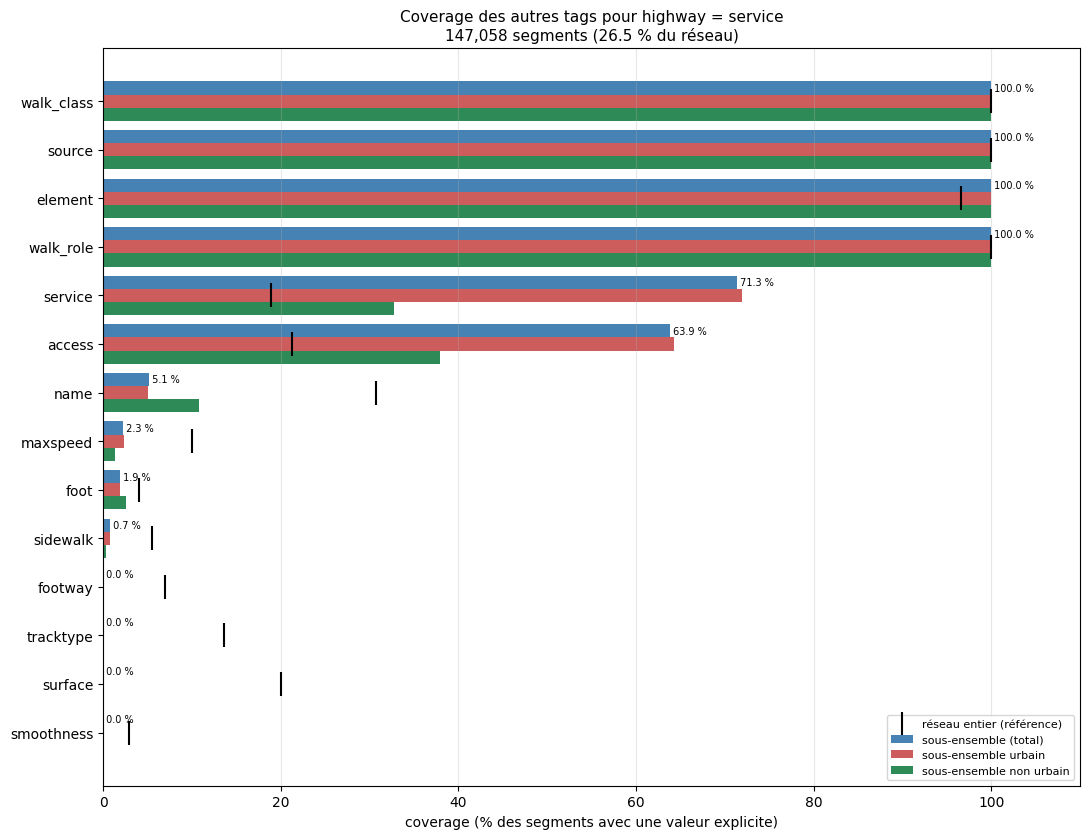

,tag,coverage_subset_%,coverage_subset_urbain_%,coverage_subset_non_urbain_%,coverage_reseau_%,n_explicit_subset,gain_vs_reseau_pts
0,walk_class,100.0,100.0,100.0,100.0,147058,0.0
1,source,100.0,100.0,100.0,100.0,147058,0.0
2,element,100.0,100.0,100.0,96.6,147058,3.4
3,walk_role,100.0,100.0,100.0,100.0,147058,0.0
4,service,71.3,71.9,32.7,18.9,104916,52.4
5,access,63.9,64.2,37.9,21.2,93903,42.6
6,name,5.1,5.0,10.8,30.7,7529,-25.6
7,maxspeed,2.3,2.3,1.4,10.0,3373,-7.7
8,foot,1.9,1.9,2.5,4.0,2860,-2.0
9,sidewalk,0.7,0.8,0.3,5.6,1097,-4.8


In [41]:
# =====================================================================
# Coverage des autres tags pour un sous-ensemble tag = valeur
#   ex. highway = footway : quelle part de ces segments a surface, lit, width... ?
#   (nécessite la cellule précédente : seg, is_urban, split_missing, candidates)
# =====================================================================

# --- Paramètres à adapter ---------------------------------------------
FILTER_TAG = "highway"
FILTER_VALUES = ["service"]   # une ou plusieurs valeurs, ex. ["footway", "path"]
OTHER_TAGS = None           # None = tous les tags candidats, sinon liste ex. ["surface", "lit", "width"]
SORT_BY = "subset"            # "subset" (coverage dans le sous-ensemble) ou "gain" (écart vs réseau entier)
HIDE_ZERO = False             # True : masquer les tags jamais renseignés dans le sous-ensemble

# --- Sous-ensemble ------------------------------------------------------
for name in ["seg", "is_urban", "split_missing", "candidates"]:
    if name not in globals():
        raise NameError(f"'{name}' introuvable : exécute d'abord la cellule d'étude statistique des tags.")
if FILTER_TAG not in seg.columns:
    raise KeyError(f"Tag '{FILTER_TAG}' absent du fichier. Disponibles : {candidates}")

filter_vals, _ = split_missing(seg[FILTER_TAG])
in_subset = filter_vals.isin([str(v) for v in FILTER_VALUES]).fillna(False).astype(bool)
n_sub = int(in_subset.sum())
if n_sub == 0:
    print(f"Aucun segment avec {FILTER_TAG} = {FILTER_VALUES}. Valeurs les plus fréquentes :")
    print(filter_vals.value_counts().head(15).to_string())
    raise ValueError("Sous-ensemble vide")

sub_urb, sub_rur = in_subset & is_urban, in_subset & ~is_urban
label = f"{FILTER_TAG} = {' | '.join(map(str, FILTER_VALUES))}"
print(f"{label} : {n_sub:,} segments ({100 * n_sub / len(seg):.1f} % du réseau) | "
      f"urbains : {int(sub_urb.sum()):,} | non urbains : {int(sub_rur.sum()):,}")

# --- Coverage des autres tags -------------------------------------------
others = [t for t in (OTHER_TAGS or candidates) if t in seg.columns and t != FILTER_TAG]

def pct(mask, ok):
    return 100 * (mask & ok).sum() / mask.sum() if mask.sum() else np.nan

rows = []
for t in others:
    _, miss = split_missing(seg[t])
    ok = ~miss
    rows.append({"tag": t,
                 "coverage_subset_%": pct(in_subset, ok),
                 "coverage_subset_urbain_%": pct(sub_urb, ok),
                 "coverage_subset_non_urbain_%": pct(sub_rur, ok),
                 "coverage_reseau_%": pct(pd.Series(True, index=seg.index), ok),
                 "n_explicit_subset": int((in_subset & ok).sum())})

cov = pd.DataFrame(rows)
cov["gain_vs_reseau_pts"] = cov["coverage_subset_%"] - cov["coverage_reseau_%"]
if HIDE_ZERO:
    cov = cov[cov["n_explicit_subset"] > 0]
cov = cov.sort_values("gain_vs_reseau_pts" if SORT_BY == "gain" else "coverage_subset_%",
                      ascending=False).reset_index(drop=True)

# --- Graphique ----------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 0.5 * len(cov) + 1.5))
y = np.arange(len(cov))
h = 0.27
ax.barh(y - h, cov["coverage_subset_%"], height=h, color="steelblue", label="sous-ensemble (total)")
ax.barh(y,     cov["coverage_subset_urbain_%"], height=h, color="indianred", label="sous-ensemble urbain")
ax.barh(y + h, cov["coverage_subset_non_urbain_%"], height=h, color="seagreen", label="sous-ensemble non urbain")
ax.scatter(cov["coverage_reseau_%"], y, marker="|", s=300, color="black", zorder=3,
           label="réseau entier (référence)")
for yi, v in zip(y, cov["coverage_subset_%"]):
    ax.text(v, yi - h, f" {v:.1f} %", va="center", fontsize=7)

ax.set_yticks(y)
ax.set_yticklabels(cov["tag"])
ax.invert_yaxis()
ax.set_xlim(0, 110)
ax.set_xlabel("coverage (% des segments avec une valeur explicite)")
ax.set_title(f"Coverage des autres tags pour {label}\n"
             f"{n_sub:,} segments ({100 * n_sub / len(seg):.1f} % du réseau)", fontsize=11)
ax.grid(axis="x", alpha=0.3)
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

display(cov.round(1))

access dans highway = service : 93,903 / 147,058 segments renseignés (63.9 %) | 15 valeurs distinctes


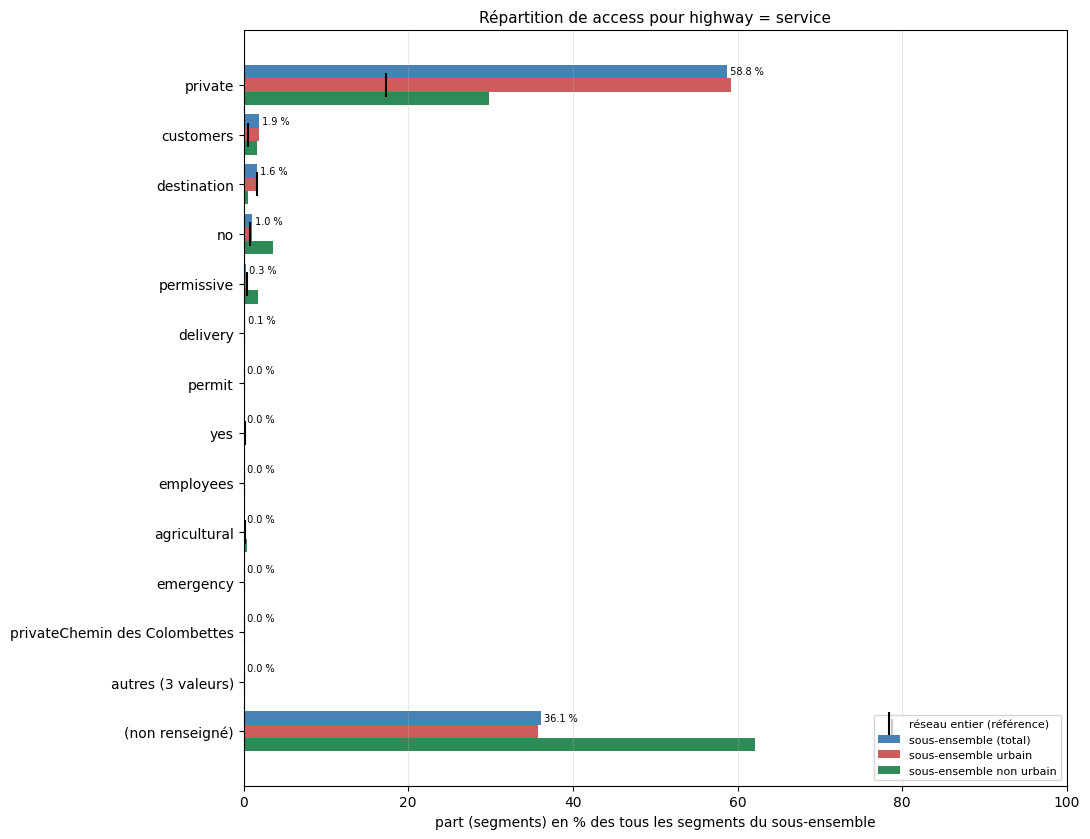

,n_subset,n_urbain,n_non_urbain,n_reseau,%_subset,%_urbain,%_non_urbain,%_reseau
access,,,,,,,,
private,86418,85784,634,96360,58.8,59.2,29.8,17.4
customers,2832,2798,34,3302,1.9,1.9,1.6,0.6
destination,2358,2346,12,9282,1.6,1.6,0.6,1.7
no,1537,1460,77,4558,1.0,1.0,3.6,0.8
permissive,475,438,37,2053,0.3,0.3,1.7,0.4
delivery,167,165,2,167,0.1,0.1,0.1,0.0
permit,35,35,0,237,0.0,0.0,0.0,0.0
yes,35,34,1,758,0.0,0.0,0.0,0.1
employees,14,14,0,14,0.0,0.0,0.0,0.0


In [42]:
# =====================================================================
# Répartition des valeurs d'un tag dans le sous-ensemble FILTER_TAG = FILTER_VALUES
#   ex. highway = footway → comment se répartit surface (asphalt, paving_stones, ...) ?
#   (nécessite la cellule précédente : in_subset, sub_urb, sub_rur, label)
# =====================================================================

# --- Paramètres à adapter ---------------------------------------------
DETAIL_TAG = "access"
TOP_N = 12                 # nb de valeurs affichées, le reste est regroupé dans "autres"
BASE = "subset"            # "subset" : % de tous les segments du sous-ensemble (non renseigné inclus)
                           # "explicit" : % des segments qui ont une valeur explicite seulement
WEIGHT = "count"           # "count" : nombre de segments | "length" : longueur (CRS métrique requis)
MISSING = "(non renseigné)"

# --- Préparation --------------------------------------------------------
if DETAIL_TAG not in seg.columns:
    raise KeyError(f"Tag '{DETAIL_TAG}' absent. Disponibles : {candidates}")

vals, miss = split_missing(seg[DETAIL_TAG])
v = vals.astype("object").where(~miss, MISSING)

if WEIGHT == "length":
    if seg.crs is None or not seg.crs.is_projected:
        raise ValueError("CRS non projeté : reprojette seg (ex. EPSG:2056) avant d'utiliser WEIGHT='length'.")
    w = seg.geometry.length
    unit = "m"
else:
    w = pd.Series(1, index=seg.index)
    unit = "segments"

def distrib(mask):
    s, ws = v[mask], w[mask]
    if BASE == "explicit":
        keep = s != MISSING
        s, ws = s[keep], ws[keep]
    c = ws.groupby(s).sum()
    tot = c.sum()
    return c, (100 * c / tot if tot else c * np.nan)

groups = {"subset": in_subset, "urbain": sub_urb, "non_urbain": sub_rur,
          "reseau": pd.Series(True, index=seg.index)}
n, p = {}, {}
for k, m in groups.items():
    n[k], p[k] = distrib(m)

tab = pd.concat({**{f"n_{k}": n[k] for k in groups},
                 **{f"%_{k}": p[k] for k in groups}}, axis=1).fillna(0)
tab = tab[tab["n_subset"] > 0].sort_values("n_subset", ascending=False)

# --- Regroupement des valeurs rares, "non renseigné" toujours en dernier --
miss_row = tab.loc[[MISSING]] if MISSING in tab.index else None
body = tab.drop(index=MISSING, errors="ignore")
if len(body) > TOP_N:
    rest = body.iloc[TOP_N:]
    body = body.iloc[:TOP_N].copy()
    body.loc[f"autres ({len(rest)} valeurs)"] = rest.sum()
tab = pd.concat([body, miss_row]) if miss_row is not None else body

# --- Résumé ---------------------------------------------------------------
n_expl = int((in_subset & ~miss).sum())
print(f"{DETAIL_TAG} dans {label} : {n_expl:,} / {int(in_subset.sum()):,} segments renseignés "
      f"({100 * n_expl / in_subset.sum():.1f} %) | {len(n['subset']) - (MISSING in n['subset'])} valeurs distinctes")

# --- Graphique ----------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 0.5 * len(tab) + 1.5))
y = np.arange(len(tab))
h = 0.27
ax.barh(y - h, tab["%_subset"], height=h, color="steelblue", label="sous-ensemble (total)")
ax.barh(y,     tab["%_urbain"], height=h, color="indianred", label="sous-ensemble urbain")
ax.barh(y + h, tab["%_non_urbain"], height=h, color="seagreen", label="sous-ensemble non urbain")
ax.scatter(tab["%_reseau"], y, marker="|", s=300, color="black", zorder=3,
           label="réseau entier (référence)")
for yi, val in zip(y, tab["%_subset"]):
    ax.text(val, yi - h, f" {val:.1f} %", va="center", fontsize=7)

ax.set_yticks(y)
ax.set_yticklabels(tab.index)
ax.invert_yaxis()
ax.set_xlim(0, max(100, tab[[c for c in tab if c.startswith("%_")]].max().max() * 1.1))
base_txt = "segments renseignés" if BASE == "explicit" else "tous les segments du sous-ensemble"
ax.set_xlabel(f"part ({unit}) en % des {base_txt}")
ax.set_title(f"Répartition de {DETAIL_TAG} pour {label}", fontsize=11)
ax.grid(axis="x", alpha=0.3)
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

n_cols = [c for c in tab if c.startswith("n_")]
tab[n_cols] = tab[n_cols].round(0).astype(int)
display(tab.round(1))